# Analysis: does a larger amount of features improve the segmentation?

This notebook does all experiments on the features computed by `extract_features.py`.
Run that script first (once, and again after adding a feature). Everything here is plain numpy / scikit-learn:

1. Load the features
2. Choose the random forest (task 1)
3. Compare feature sets (task 2)
4. Feature importance with SHAP (task 3)
5. Leave one feature group out (task 4)
6. Robustness to image noise (task 5)

A **feature set** is just a list of column names: `X[:, columns(names)]`. Nothing has to be recomputed to try another set.

In [1]:
import glob
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import SimpleITK as sitk
from scipy import stats
from sklearn.ensemble import RandomForestClassifier

import mialab.utilities.pipeline_utilities as putil

FEATURE_DIR = 'features'
ATLAS_FILE = '../data/atlas/mni_icbm152_t1_tal_nlin_sym_09a.nii.gz'
LABELS = {1: 'WhiteMatter', 2: 'GreyMatter', 3: 'Hippocampus', 4: 'Amygdala', 5: 'Thalamus'}

## 0. Load the features

- `train`: the randomly sampled training voxels of the 20 training subjects (about 5'000 per subject).
- `test`: one entry per test subject with **all** voxels inside the brain mask (about 1.8 million per subject).
  Voxels outside the brain mask are background, so they don't need a prediction.

In [2]:
def load_test(folder):
    """Loads all test subjects of a folder into a dict {subject: npz data}."""
    files = sorted(glob.glob(os.path.join(folder, 'test_*.npz')))
    return {os.path.basename(f)[5:-4]: dict(np.load(f)) for f in files}


train = np.load(os.path.join(FEATURE_DIR, 'train.npz'))
X_train, y_train = train['X'], train['y']
FEATURE_NAMES = list(train['feature_names'])
test = load_test(FEATURE_DIR)

print('features:', FEATURE_NAMES)
print('training voxels:', X_train.shape, ' test subjects:', list(test))
print('training voxels per label:', dict(zip(*np.unique(y_train, return_counts=True))))

features: ['ATLAS_COORD_0', 'ATLAS_COORD_1', 'ATLAS_COORD_2', 'T1w_INTENSITY', 'T1w_GRADIENT_INTENSITY', 'T2w_INTENSITY', 'T2w_GRADIENT_INTENSITY']
training voxels: (132880, 7)  test subjects: ['117122', '118528', '118730', '118932', '120111', '122317', '122620', '123117', '123925', '124422']
training voxels per label: {0: 45817, 1: 38969, 2: 31234, 3: 7091, 4: 2598, 5: 7171}


In [3]:
def columns(names):
    """Column indices of a list of feature names."""
    return [FEATURE_NAMES.index(n) for n in names]


def dice(prediction, truth, label):
    """Dice coefficient of one label: 2 |A and B| / (|A| + |B|)."""
    a, b = prediction == label, truth == label
    return 2 * np.sum(a & b) / (np.sum(a) + np.sum(b))


atlas = sitk.ReadImage(ATLAS_FILE)  # all images are registered to the atlas, so they share its geometry


def to_image(values, brain_index):
    """Puts the values of the brain voxels back into a full 3-D image (needed for HD95)."""
    volume = np.zeros(atlas.GetSize()[::-1], dtype=np.uint8)
    volume.flat[brain_index] = values
    image = sitk.GetImageFromArray(volume)
    image.CopyInformation(atlas)
    return image


evaluator = putil.init_evaluator()  # the pipeline's evaluator: Dice and HD95 (pymia)

In [4]:
def train_forest(names, seed=0, **forest_params):
    """Trains a random forest on the given feature columns."""
    params = dict(n_estimators=50, max_depth=20, max_features='sqrt', n_jobs=-1)
    params.update(forest_params)
    forest = RandomForestClassifier(random_state=seed, **params)
    forest.fit(X_train[:, columns(names)], y_train)
    return forest


def evaluate(forest, names, test_data=None, with_hd95=False, experiment=''):
    """Dice (and optionally HD95) per test subject and structure, as a table with one row per value."""
    rows = []
    for subject, data in (test_data or test).items():
        prediction = forest.predict(data['X'][:, columns(names)])
        if with_hd95:  # the pipeline's evaluator needs images
            evaluator.evaluate(to_image(prediction, data['brain_index']), to_image(data['y'], data['brain_index']),
                               subject)
            rows += [{'experiment': experiment, 'subject': subject, 'label': r.label, 'metric': r.metric,
                      'value': r.value} for r in evaluator.results]
            evaluator.clear()
        else:  # Dice only, computed directly with numpy (fast)
            rows += [{'experiment': experiment, 'subject': subject, 'label': name, 'metric': 'DICE',
                      'value': dice(prediction, data['y'], label)} for label, name in LABELS.items()]
    return pd.DataFrame(rows)


def summary(results):
    """Mean and std over the test subjects, one column per experiment."""
    table = results.groupby(['metric', 'label', 'experiment'])['value'].agg(['mean', 'std'])
    return (table['mean'].round(3).astype(str) + ' ± ' + table['std'].round(3).astype(str)).unstack()


def wilcoxon(results, baseline, other, metric='DICE'):
    """Paired Wilcoxon test per structure: is `other` different from `baseline`?"""
    rows = []
    for label in LABELS.values():
        r = results[(results.metric == metric) & (results.label == label)]
        a = r[r.experiment == baseline].sort_values('subject').value.values
        b = r[r.experiment == other].sort_values('subject').value.values
        rows.append({'label': label, 'median_diff': np.median(b - a),
                     'p_value': stats.wilcoxon(b, a).pvalue if np.any(a != b) else 1.0})
    return pd.DataFrame(rows)

## 1. Choose the random forest

The provided forest (1 tree, depth 5) is too weak: the amygdala is never predicted. Try a few settings on the
**provided features**, pick one with good Dice and acceptable run time, and keep it fixed for everything below.

In [5]:
BASELINE = ['ATLAS_COORD_0', 'ATLAS_COORD_1', 'ATLAS_COORD_2', 'T1w_INTENSITY', 'T1w_GRADIENT_INTENSITY']

forest_results = []
for n_estimators, max_depth in [(10, 10), (50, 20), (100, 40)]:  # add more settings here, e.g. (100, 25), (100, None)
    forest = train_forest(BASELINE, n_estimators=n_estimators, max_depth=max_depth)
    forest_results.append(evaluate(forest, BASELINE, experiment=f'{n_estimators} trees, depth {max_depth}'))
forest_results = pd.concat(forest_results)
summary(forest_results)

experiment         10 trees, depth 10 100 trees, depth 40 50 trees, depth 20
metric label                                                                
DICE   Amygdala         0.554 ± 0.046       0.531 ± 0.045      0.524 ± 0.047
       GreyMatter        0.69 ± 0.012       0.718 ± 0.011      0.717 ± 0.011
       Hippocampus      0.336 ± 0.009       0.551 ± 0.015      0.527 ± 0.015
       Thalamus         0.726 ± 0.028       0.768 ± 0.024      0.763 ± 0.025
       WhiteMatter      0.816 ± 0.019        0.824 ± 0.02       0.824 ± 0.02

In [6]:
FOREST = dict(n_estimators=50, max_depth=20)  # the chosen setting: don't change it after this point

## 2. Compare feature sets

Each feature set is a list of names. Train with 3 seeds to see how much the result changes by chance alone.

In [7]:
FEATURE_SETS = {
    'baseline': BASELINE,
    'baseline + T2': BASELINE + ['T2w_INTENSITY', 'T2w_GRADIENT_INTENSITY'],
    'all': FEATURE_NAMES,
}
SEEDS = [0, 1, 2]

results = []
for name, names in FEATURE_SETS.items():
    for seed in SEEDS:
        forest = train_forest(names, seed=seed, **FOREST)
        r = evaluate(forest, names, experiment=name)
        r['seed'] = seed
        results.append(r)
results = pd.concat(results)
# average the seeds per subject, so every subject counts once
results_mean = results.groupby(['experiment', 'subject', 'label', 'metric'], as_index=False)['value'].mean()
summary(results_mean)

experiment                    all       baseline  baseline + T2
metric label                                                   
DICE   Amygdala     0.533 ± 0.046  0.524 ± 0.045  0.533 ± 0.046
       GreyMatter   0.718 ± 0.011  0.717 ± 0.011  0.718 ± 0.011
       Hippocampus  0.496 ± 0.015  0.527 ± 0.016  0.496 ± 0.015
       Thalamus     0.763 ± 0.023  0.762 ± 0.026  0.763 ± 0.023
       WhiteMatter    0.82 ± 0.02   0.824 ± 0.02    0.82 ± 0.02

         label  median_diff   p_value
0  WhiteMatter    -0.004292  0.001953
1   GreyMatter     0.001269  0.003906
2  Hippocampus    -0.030346  0.001953
3     Amygdala     0.008550  0.001953
4     Thalamus     0.002126  0.492188


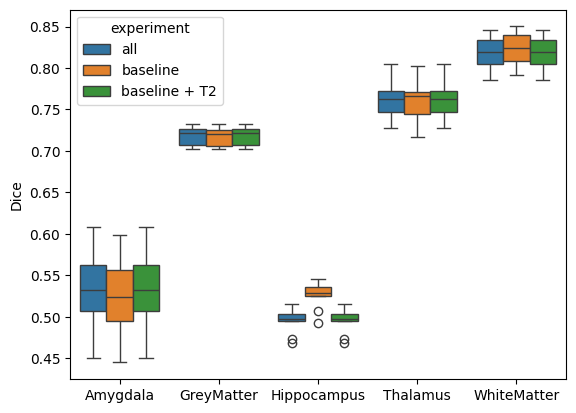

In [8]:
print(wilcoxon(results_mean, 'baseline', 'baseline + T2'))

sns.boxplot(data=results_mean[results_mean.metric == 'DICE'], x='label', y='value', hue='experiment')
plt.ylabel('Dice'); plt.xlabel(''); plt.show()

## 3. Feature importance with SHAP

SHAP splits each prediction into one contribution per feature. The mean absolute SHAP value of a feature, **per
structure**, says how much the forest relies on that feature to recognise the structure.
A sample of test voxels is enough (SHAP is slow).

c:\Users\marcl\development\PythonProjects\mialab_simple\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


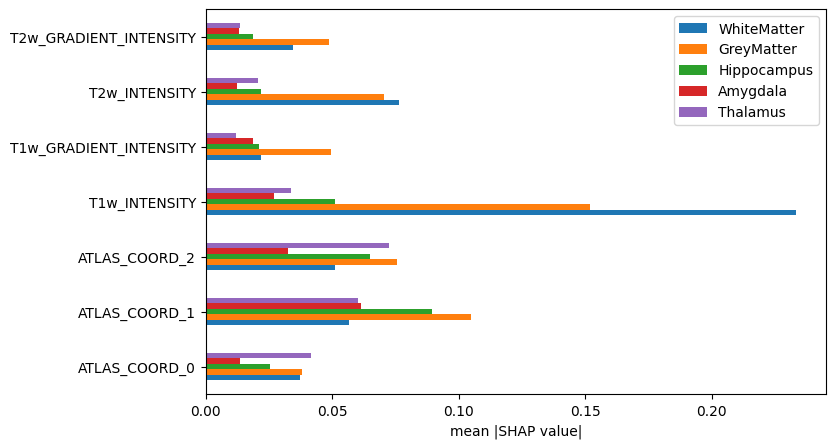

,Background,WhiteMatter,GreyMatter,Hippocampus,Amygdala,Thalamus
ATLAS_COORD_0,0.008375,0.037416,0.037825,0.025462,0.013334,0.041547
ATLAS_COORD_1,0.013255,0.056635,0.104845,0.089440,0.061316,0.060282
ATLAS_COORD_2,0.017605,0.051170,0.075638,0.064854,0.032514,0.072259
T1w_INTENSITY,0.052286,0.233414,0.151739,0.050877,0.026863,0.033496
T1w_GRADIENT_INTENSITY,0.113509,0.021908,0.049347,0.021070,0.018811,0.011902
T2w_INTENSITY,0.029315,0.076392,0.070233,0.021860,0.012367,0.020654
T2w_GRADIENT_INTENSITY,0.124549,0.034551,0.048837,0.018804,0.012939,0.013494


In [9]:
import shap

names = FEATURE_SETS['all']
forest = train_forest(names, **FOREST)

# a sample of test voxels with the same number of voxels per label (otherwise background dominates)
rng = np.random.default_rng(0)
first = next(iter(test.values()))
sample = np.concatenate([rng.choice(np.flatnonzero(first['y'] == label), 100, replace=False) for label in range(6)])
X_sample = first['X'][sample][:, columns(names)]

shap_values = shap.TreeExplainer(forest).shap_values(X_sample)
shap_values = np.stack(shap_values, axis=-1) if isinstance(shap_values, list) else shap_values  # (voxels, features, classes)

importance = pd.DataFrame({LABELS.get(c, 'Background'): np.abs(shap_values[:, :, i]).mean(axis=0)
                           for i, c in enumerate(forest.classes_)}, index=names)
importance.drop(columns='Background').plot.barh(figsize=(8, 5))
plt.xlabel('mean |SHAP value|'); plt.show()
importance

## 4. Leave one feature group out

How much worse is the segmentation without a group? A large drop means the group carries information the other
features can't replace. Compare with SHAP: a feature can be used a lot (high SHAP) but still be replaceable.

In [10]:
GROUPS = {
    'coordinates': ['ATLAS_COORD_0', 'ATLAS_COORD_1', 'ATLAS_COORD_2'],
    'T1': ['T1w_INTENSITY', 'T1w_GRADIENT_INTENSITY'],
    'T2': ['T2w_INTENSITY', 'T2w_GRADIENT_INTENSITY'],
    'gradients': ['T1w_GRADIENT_INTENSITY', 'T2w_GRADIENT_INTENSITY'],
}

ablation = [evaluate(train_forest(FEATURE_NAMES, **FOREST), FEATURE_NAMES, experiment='all')]
for group, removed in GROUPS.items():
    names = [n for n in FEATURE_NAMES if n not in removed]
    ablation.append(evaluate(train_forest(names, **FOREST), names, experiment=f'without {group}'))
ablation = pd.concat(ablation)
summary(ablation)

experiment                    all     without T1     without T2  \
metric label                                                      
DICE   Amygdala     0.528 ± 0.046  0.507 ± 0.046  0.524 ± 0.047   
       GreyMatter   0.718 ± 0.011  0.705 ± 0.011  0.717 ± 0.011   
       Hippocampus  0.494 ± 0.016  0.474 ± 0.015  0.527 ± 0.015   
       Thalamus     0.765 ± 0.023  0.751 ± 0.017  0.763 ± 0.025   
       WhiteMatter   0.821 ± 0.02  0.807 ± 0.022   0.824 ± 0.02   

experiment         without coordinates without gradients  
metric label                                              
DICE   Amygdala           0.096 ± 0.04     0.516 ± 0.047  
       GreyMatter          0.68 ± 0.01     0.719 ± 0.011  
       Hippocampus       0.076 ± 0.016     0.518 ± 0.015  
       Thalamus          0.114 ± 0.021      0.77 ± 0.023  
       WhiteMatter       0.789 ± 0.017      0.825 ± 0.02

## 5. Robustness to image noise

The frozen forests (trained on clean images) are tested on images with Gaussian noise. Create the noisy features
first with `python extract_features.py --noise 0.1 0.2 0.5` (noise in units of the brain's intensity std).
Which feature set loses most, and which structures suffer?

In [11]:
noise_results = []
for name in ['baseline', 'all']:
    names = FEATURE_SETS[name]
    forest = train_forest(names, **FOREST)
    noise_results.append(evaluate(forest, names, experiment=f'{name}, noise 0'))
    for folder in sorted(glob.glob(os.path.join(FEATURE_DIR, 'noise_*'))):
        level = folder.split('noise_')[-1]
        noise_results.append(evaluate(forest, names, test_data=load_test(folder), experiment=f'{name}, noise {level}'))
noise_results = pd.concat(noise_results)
summary(noise_results)

experiment           all, noise 0 baseline, noise 0
metric label                                       
DICE   Amygdala     0.528 ± 0.046     0.524 ± 0.047
       GreyMatter   0.718 ± 0.011     0.717 ± 0.011
       Hippocampus  0.494 ± 0.016     0.527 ± 0.015
       Thalamus     0.765 ± 0.023     0.763 ± 0.025
       WhiteMatter   0.821 ± 0.02      0.824 ± 0.02

## 6. HD95 for the final comparison

HD95 (`HDRFDST95`, 95th percentile Hausdorff distance in mm) is slower to compute, so it is only computed for the final models. It is `inf` when a structure is not predicted at all.

In [ ]:
final = []
for name, names in FEATURE_SETS.items():
    final.append(evaluate(train_forest(names, **FOREST), names, with_hd95=True, experiment=name))
final = pd.concat(final)
summary(final)